# Diabetes readmission: results and evidence

## Summary
This notebook reviews **two separate experiments**: the original project's archived cross-validation tables, and a new patient-disjoint logistic baseline. It does not retrain models or merge their scores into a common ranking.

The original CSV summary records LightGBM at ROC-AUC **0.654** and F1 **0.226**. These values are inherited evidence, not a fresh reproduction. The new baseline's held-out results are loaded directly from its execution manifest below.

Both experiments have limited predictive performance. They illustrate the importance of minority-class metrics, clear data splits and validation-only threshold selection.

## Context and methods

**Question:** What do the committed model outputs support, and where are their limits?

- Positive outcome: readmission in **fewer than 30 days**; `NO` and `>30` form the negative class.
- Historical evidence: `reports/tables/03_model_comparison.csv`, `03_tuned_model_comparison.csv`, and `05_cluster_profiles.csv`.
- New baseline: `reports/portfolio/baseline/metrics.json`, generated by `python -m src.baseline` on the original UCI CSV.
- The baseline fits preprocessing on training data only, chooses a threshold using validation F1, and reports test performance once the threshold is fixed.
- The historical tables lack a complete run manifest; do not infer the exact run settings from today's notebook defaults.

### Key assumptions and limits
The baseline keeps the smallest eligible encounter ID per patient as the original preprocessing does; this is not a verified timestamp. It uses one random split, not temporal or external validation. Cost examples in the original project are assumptions, not established savings or official penalty schedules.

In [1]:
# Resolve imports from either the repository root or notebooks/.
import sys
from pathlib import Path
PROJECT_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / 'src' / 'paths.py').exists() and (p / 'notebooks').is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT))
from src.paths import RAW_DATA_DIR, PROCESSED_DATA_DIR, TABLES_DIR
TABLES_DIR.mkdir(parents=True, exist_ok=True)
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, GOLD, INK = '#2563A6', '#B7791F', '#263445'
PORTFOLIO_DIR = PROJECT_ROOT / 'reports' / 'portfolio'
PORTFOLIO_DIR.mkdir(parents=True, exist_ok=True)

## Data and provenance

In [2]:
paths = {
    'Historical CV': TABLES_DIR / '03_model_comparison.csv',
    'Historical tuned CV': TABLES_DIR / '03_tuned_model_comparison.csv',
    'Historical clusters': TABLES_DIR / '05_cluster_profiles.csv',
    'New baseline': PORTFOLIO_DIR / 'baseline' / 'metrics.json',
}
provenance = pd.DataFrame([
    {'artifact': label, 'path': str(path.relative_to(PROJECT_ROOT)), 'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
    for label, path in paths.items()
])
display(provenance)
historical = pd.read_csv(paths['Historical CV']).set_index('model')
tuned = pd.read_csv(paths['Historical tuned CV']).set_index('model')
clusters = pd.read_csv(paths['Historical clusters']).set_index('cluster')
baseline = json.loads(paths['New baseline'].read_text())
for frame in (historical, tuned):
    assert frame.index.is_unique
    for column in ['f1_mean', 'auc_roc_mean', 'auprc_mean', 'recall_mean', 'precision_mean']:
        assert frame[column].between(0, 1).all(), f'Invalid values in {column}'
assert not any(baseline['patient_overlap'].values())
provenance.to_csv(PORTFOLIO_DIR / 'summary_sources.csv', index=False)

,artifact,path,sha256
0,Historical CV,reports/tables/03_model_comparison.csv,cd76f304b339cdf5677f7aedd5b6797ccbf1b7af7285fb...
1,Historical tuned CV,reports/tables/03_tuned_model_comparison.csv,c8fbd5e9d2735aca4a5de6f0a429299c75c8fea8d315e9...
2,Historical clusters,reports/tables/05_cluster_profiles.csv,a34ef0c473c37909e122ae1ce86aa3f3de640f7ba1f3b6...
3,New baseline,reports/portfolio/baseline/metrics.json,50bf2245fa0e258a82a4f375300798434a42b64de75fb1...


## Results

### New baseline: held-out test performance
The table below is computed from the committed run manifest. The threshold was selected on validation data. No confidence interval is reported because this experiment used a single split.

In [3]:
display(pd.DataFrame(baseline['split_counts']).T.rename_axis('partition'))
display(Markdown(f"**Raw encounters:** {baseline['raw_rows']:,}; **eligible unique patients:** {baseline['eligible_unique_patients']:,}. "
                 f"**Patient overlap across partitions:** {sum(baseline['patient_overlap'].values())}."))
scores = pd.DataFrame({
    'Validation-selected threshold': baseline['test_at_selected_threshold'],
    'Default threshold 0.50': baseline['test_at_default_threshold'],
}).drop(index='confusion_matrix').astype(float)
display(scores.round(4))
display(Markdown(f"ROC-AUC is **{scores.loc['roc_auc'].iloc[0]:.3f}**, and average precision is **{scores.loc['average_precision'].iloc[0]:.3f}**. "
                 "Changing the classification threshold trades precision against recall; it does not change ranking metrics."))

,rows,positive
partition,,
train,48993,4400
validation,10498,942
test,10499,943


**Raw encounters:** 101,766; **eligible unique patients:** 69,990. **Patient overlap across partitions:** 0.

,Validation-selected threshold,Default threshold 0.50
roc_auc,0.6301,0.6301
average_precision,0.1560,0.1560
f1,0.2217,0.2179
precision,0.1529,0.1377
recall,0.4030,0.5228
balanced_accuracy,0.5913,0.5998
brier_score,0.2185,0.2185
threshold,0.5600,0.5000


ROC-AUC is **0.630**, and average precision is **0.156**. Changing the classification threshold trades precision against recall; it does not change ranking metrics.

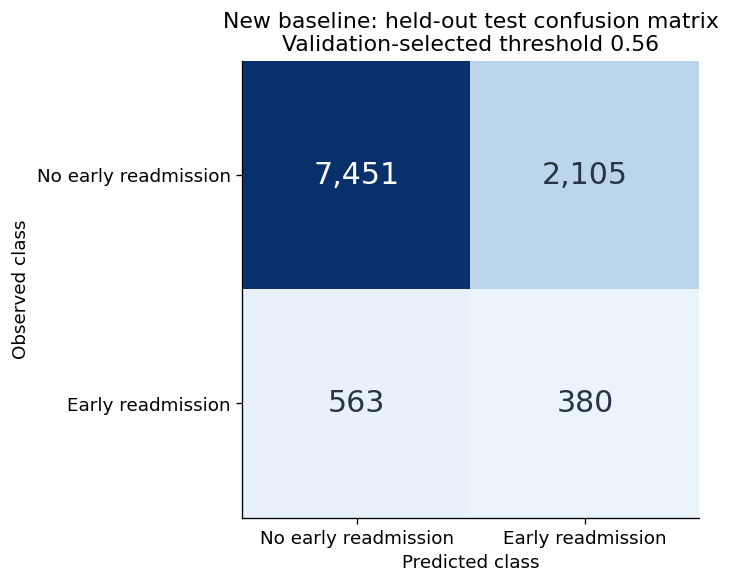

In [4]:
cm = baseline['test_at_selected_threshold']['confusion_matrix']
matrix = np.array([[cm['tn'], cm['fp']], [cm['fn'], cm['tp']]])
fig, ax = plt.subplots(figsize=(6.6, 5))
ax.imshow(matrix, cmap='Blues', vmin=0, vmax=matrix.max())
for (row, column), value in np.ndenumerate(matrix):
    ax.text(column, row, f'{value:,}', ha='center', va='center', fontsize=18,
            color='white' if value > matrix.max() / 2 else INK)
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['No early readmission', 'Early readmission'],
       yticklabels=['No early readmission', 'Early readmission'], xlabel='Predicted class', ylabel='Observed class',
       title=f"New baseline: held-out test confusion matrix\nValidation-selected threshold {baseline['selection']['threshold']:.2f}")
fig.tight_layout()
fig.savefig(PORTFOLIO_DIR / 'baseline_confusion_matrix.png', bbox_inches='tight')
plt.show()

### Historical cross-validation results
These are archived fold means, not the new baseline's held-out scores. `auprc_mean` in the original implementation uses **average precision**, while `pr_auc_mean` uses trapezoidal integration; they should not be treated as interchangeable.

Error bars below reproduce the stored 95% fold-based intervals. They have not been independently re-estimated, and overlapping intervals do not establish a significance result.

,auc_roc_mean,auprc_mean,f1_mean,precision_mean,recall_mean
model,,,,,
lightgbm,0.6542,0.1791,0.2259,0.1439,0.5260
random_forest,0.6231,0.1516,0.1934,0.1122,0.7017
gradient_boosting,0.6284,0.1545,0.1864,0.1053,0.8095
knn,0.5492,0.1019,0.1743,0.1008,0.6422
sgd_classifier,0.5946,0.1316,0.1699,0.0940,0.8837
logistic_regression,0.6041,0.1430,0.1694,0.0933,0.9177
naive_bayes,0.5124,0.0919,0.1676,0.0920,0.9364
xgboost,0.6200,0.1594,0.1666,0.0910,0.9901
one_r,0.5805,0.1083,0.1648,0.0898,1.0000


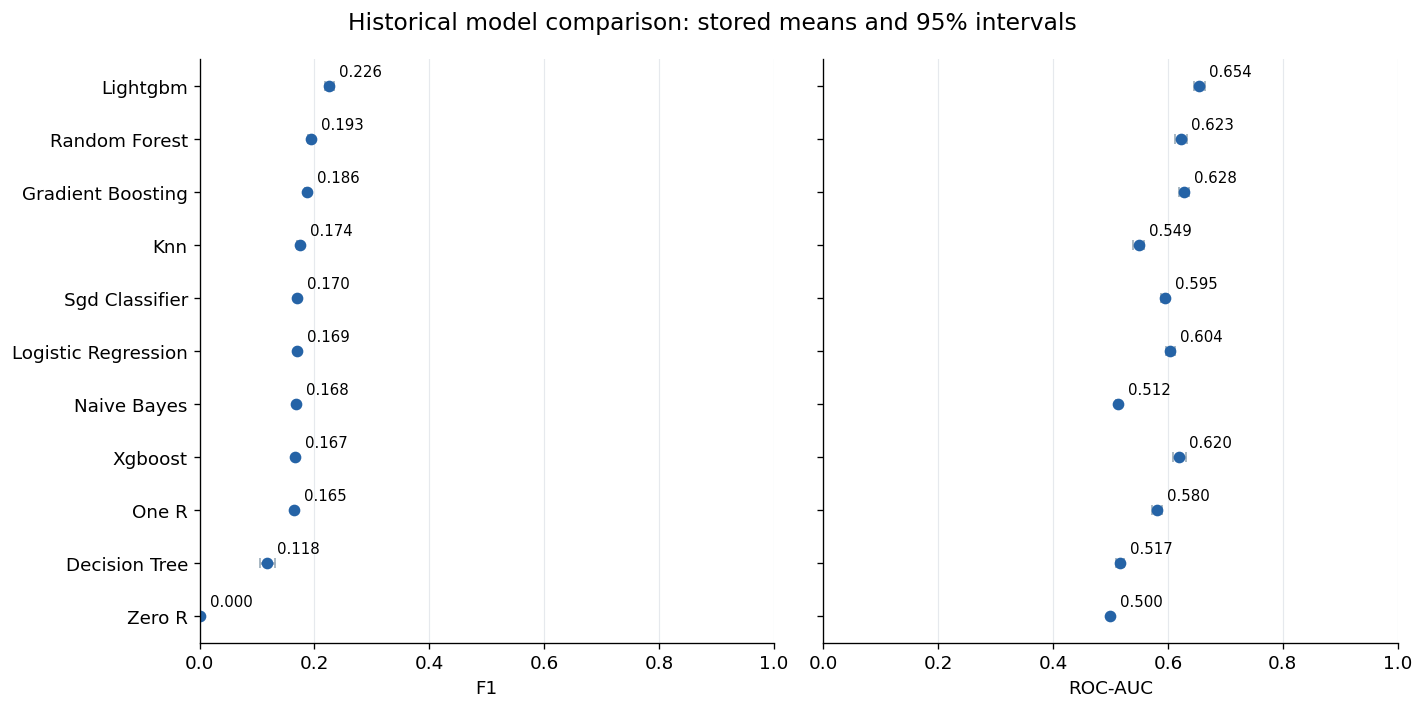

In [5]:
columns = ['auc_roc_mean', 'auprc_mean', 'f1_mean', 'precision_mean', 'recall_mean']
display(historical[columns].sort_values('f1_mean', ascending=False).round(4))
ranked = historical.sort_values('f1_mean')
labels = [name.replace('_', ' ').title() for name in ranked.index]
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
for ax, metric, title in zip(axes, ['f1', 'auc_roc'], ['F1', 'ROC-AUC']):
    means = ranked[f'{metric}_mean'].to_numpy()
    lower = ranked[f'{metric}_ci_lower'].to_numpy()
    upper = ranked[f'{metric}_ci_upper'].to_numpy()
    ax.errorbar(means, np.arange(len(ranked)), xerr=np.vstack([means-lower, upper-means]),
                fmt='o', color=BLUE, ecolor='#9AABB9', capsize=3)
    for y, value in enumerate(means):
        ax.annotate(f'{value:.3f}', (value, y), xytext=(6, 6), textcoords='offset points', fontsize=9)
    ax.set_xlabel(title)
    ax.set_xlim(0, 1)
    ax.grid(axis='x', color='#E6E9ED', linewidth=.7)
    ax.set_axisbelow(True)
axes[0].set_yticks(np.arange(len(labels)), labels)
fig.suptitle('Historical model comparison: stored means and 95% intervals', fontsize=14)
fig.tight_layout()
fig.savefig(PORTFOLIO_DIR / 'historical_model_comparison.png', bbox_inches='tight')
plt.show()

### Historical tuned results and clusters
Tuned and initial runs used different settings, including threshold behavior. The tables below are separate evidence; subtracting their scores would not isolate the effect of tuning.

Cluster profiles contain mean clinical features only. This CSV does **not** include cluster sizes or readmission rates, so it does not support an estimate of risk or uncertainty for each cluster.

In [6]:
display(tuned[columns].sort_values('f1_mean', ascending=False).round(4))
display(clusters.round(2))

,auc_roc_mean,auprc_mean,f1_mean,precision_mean,recall_mean
model,,,,,
sgd_classifier,0.6208,0.1475,0.2086,0.1307,0.5159
gradient_boosting,0.6400,0.1464,0.0697,0.1808,0.0434
knn,0.5301,0.1005,0.0630,0.1524,0.0398
lightgbm,0.6225,0.1566,0.0479,0.3371,0.0259
random_forest,0.6183,0.1553,0.0004,0.0500,0.0002


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
cluster,,,,,,,,
0,4.29,47.74,1.04,14.69,0.26,0.13,0.18,7.46
1,4.18,36.74,1.89,16.88,0.33,0.08,0.18,7.00
2,4.82,42.08,1.70,15.96,0.08,0.02,0.05,6.58


## Takeaways

- The reproducible baseline demonstrates data loading, patient-level separation, training-only preprocessing, validation-only threshold selection, and held-out evaluation.
- Its modest ROC-AUC and average precision leave substantial room for improvement. Class weighting also means its probabilities should not be assumed calibrated.
- Historical LightGBM results are useful project evidence, but do not establish a deployed or clinically validated system.
- A meaningful next experiment would use a pre-specified split, training-only feature selection, calibrated probabilities, and repeated evaluation. Temporal or external validation requires suitable additional data.
- Original reports and slides remain available as submitted academic artifacts. Their result statements should be interpreted alongside these reproducibility limits.

## Sources

- [UCI dataset and citation](https://doi.org/10.24432/C5230J)
- [Original project](https://github.com/chrisindris/CP8305FP/tree/d340d61aa0aa7f7828409dfeae4f27c437c50d4a)
- [Project bibliography](../reports/references.bib)
